In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Make charts look nicer
sns.set_style("whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
#Load the dataset
df = pd.read_csv("../data/processed/superstore_cleaned.csv")
df.head()

,category,city,country,customer_id,customer_name,discount,market,column,order_date,order_id,...,sub_category,order_year,order_month,order_quarter,order_day_of_week,is_weekend,order_week,discount_bin,profit_margin,sales_per_unit
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,Us,1,2011-01-07,CA-2011-130813,...,Paper,2011,1,1,4,0,1,0-5%,49.11,6.33
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,Us,1,2011-01-21,CA-2011-148614,...,Paper,2011,1,1,4,0,3,0-5%,48.91,9.50
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,Us,1,2011-08-05,CA-2011-118962,...,Paper,2011,8,3,4,0,31,0-5%,46.87,7.00
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,Us,1,2011-08-05,CA-2011-118962,...,Paper,2011,8,3,4,0,31,0-5%,47.98,55.50
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,Us,1,2011-09-29,CA-2011-146969,...,Paper,2011,9,3,3,0,39,0-5%,51.84,6.00


In [3]:
#Check dataset shape
print("Rows, Columns:", df.shape)

Rows, Columns: (51290, 32)


In [4]:
#View column names
df.columns.tolist()

['category',
 'city',
 'country',
 'customer_id',
 'customer_name',
 'discount',
 'market',
 'column',
 'order_date',
 'order_id',
 'order_priority',
 'product_id',
 'product_name',
 'profit',
 'quantity',
 'region',
 'sales',
 'segment',
 'ship_date',
 'ship_mode',
 'shipping_cost',
 'state',
 'sub_category',
 'order_year',
 'order_month',
 'order_quarter',
 'order_day_of_week',
 'is_weekend',
 'order_week',
 'discount_bin',
 'profit_margin',
 'sales_per_unit']

In [5]:
#Basic data overview
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   category           51290 non-null  object 
 1   city               51290 non-null  object 
 2   country            51290 non-null  object 
 3   customer_id        51290 non-null  object 
 4   customer_name      51290 non-null  object 
 5   discount           51290 non-null  float64
 6   market             51290 non-null  object 
 7   column             51290 non-null  int64  
 8   order_date         51290 non-null  object 
 9   order_id           51290 non-null  object 
 10  order_priority     51290 non-null  object 
 11  product_id         51290 non-null  object 
 12  product_name       51290 non-null  object 
 13  profit             51290 non-null  float64
 14  quantity           51290 non-null  int64  
 15  region             51290 non-null  object 
 16  sales              512

In [6]:
df.describe()

,discount,column,profit,quantity,sales,shipping_cost,order_year,order_month,order_quarter,order_day_of_week,is_weekend,order_week,profit_margin,sales_per_unit
count,51290.000000,51290.0,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000,51290.000000
mean,0.142908,1.0,28.610982,3.476545,246.498440,26.375818,2012.777208,7.522636,2.793235,2.343264,0.108598,30.675687,-inf,71.659962
std,0.212280,0.0,174.340972,2.278766,487.567175,57.296810,1.098931,3.300056,1.066015,1.671486,0.311137,14.535168,NaN,113.581091
min,0.000000,1.0,-6599.978000,1.000000,0.000000,0.002000,2011.000000,1.000000,1.000000,0.000000,0.000000,1.000000,-inf,0.000000
25%,0.000000,1.0,0.000000,2.000000,31.000000,2.610000,2012.000000,5.000000,2.000000,1.000000,0.000000,20.000000,0.000,12.000000
50%,0.000000,1.0,9.240000,3.000000,85.000000,7.790000,2013.000000,8.000000,3.000000,2.000000,0.000000,33.000000,16.925,29.500000
75%,0.200000,1.0,36.810000,5.000000,251.000000,24.450000,2014.000000,10.000000,4.000000,4.000000,0.000000,44.000000,33.310,82.000000
max,0.850000,1.0,8399.976000,14.000000,22638.000000,933.570000,2014.000000,12.000000,4.000000,6.000000,1.000000,52.000000,58.280,3773.000000


In [7]:
#Missing values check
df.isnull().sum()

category             0
city                 0
country              0
customer_id          0
customer_name        0
discount             0
market               0
column               0
order_date           0
order_id             0
order_priority       0
product_id           0
product_name         0
profit               0
quantity             0
region               0
sales                0
segment              0
ship_date            0
ship_mode            0
shipping_cost        0
state                0
sub_category         0
order_year           0
order_month          0
order_quarter        0
order_day_of_week    0
is_weekend           0
order_week           0
discount_bin         0
profit_margin        0
sales_per_unit       0
dtype: int64

In [8]:
# Convert order_date to datetime
df["order_date"] = pd.to_datetime(df["order_date"])

# Date-based columns
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month
df["year_month"] = df["order_date"].dt.to_period("M").astype(str)

# Profit margin
df["profit_margin"] = df["profit"] / df["sales"]

# Replace inf values if any sales = 0
df["profit_margin"] = df["profit_margin"].replace([np.inf, -np.inf], np.nan)

# Discount bands
df["discount_band"] = pd.cut(
    df["discount"],
    bins=[-0.01, 0, 0.10, 0.20, 0.30, 0.40, 1.00],
    labels=["0%", "1-10%", "11-20%", "21-30%", "31-40%", "40%+"]
)

# Flag loss-making rows
df["is_loss_order"] = np.where(df["profit"] < 0, 1, 0)

print("Derived columns created successfully.")

Derived columns created successfully.


In [9]:
#Check the new columns
df[[
    "order_date",
    "order_year",
    "order_month",
    "year_month",
    "profit_margin",
    "discount_band",
    "is_loss_order"
]].head()

,order_date,order_year,order_month,year_month,profit_margin,discount_band,is_loss_order
0,2011-01-07,2011,1,2011-01,0.491116,0%,0
1,2011-01-21,2011,1,2011-01,0.489095,0%,0
2,2011-08-05,2011,8,2011-08,0.468657,0%,0
3,2011-08-05,2011,8,2011-08,0.479827,0%,0
4,2011-09-29,2011,9,2011-09,0.518400,0%,0


In [11]:
#Save the updated dataset
df.to_csv("../data/processed/superstore_cleaned.csv", index=False)
print("Updated dataset saved.")

Updated dataset saved.


In [12]:
# ============================================================
# EDA (EXPLORATORY DATA ANALYSIS)
# Purpose:
# Understand the business at a high level before deep analysis.
# This section creates the key KPIs and summary charts.
# ============================================================


# ============================================================
# # 1. OVERALL BUSINESS KPIs
# Purpose:
# Calculate the most important company-wide metrics.
# ============================================================

## Total Sales
# Total revenue generated.
total_sales = df["sales"].sum()

## Total Profit
# Total earnings after costs.
total_profit = df["profit"].sum()

## Profit Margin
# Percentage of sales converted into profit.
profit_margin = (total_profit / total_sales) * 100

## Total Orders
# Number of unique orders.
total_orders = df["order_id"].nunique()

## Total Customers
# Number of unique customers.
total_customers = df["customer_id"].nunique()

## Average Order Value (AOV)
# Average revenue per order.
average_order_value = total_sales / total_orders

## Average Discount
# Mean discount offered across all transactions.
average_discount = df["discount"].mean() * 100

## Loss-Making Orders
# Number of rows where profit is negative.
loss_orders = df[df["profit"] < 0].shape[0]

## Loss Order Rate
# Percentage of rows that made a loss.
loss_order_rate = (loss_orders / len(df)) * 100


# ============================================================
# # 2. PRINT KPI SUMMARY
# Purpose:
# Display all top-level metrics in one place.
# ============================================================

print("========== BUSINESS KPI SUMMARY ==========")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")
print(f"Average Discount: {average_discount:.2f}%")
print(f"Loss-Making Rows: {loss_orders:,}")
print(f"Loss Order Rate: {loss_order_rate:.2f}%")
print("==========================================")


# ============================================================
# # 3. MONTHLY SALES & PROFIT TREND
# Purpose:
# Analyze how the business performs over time.
# ============================================================

## Aggregate by month
monthly_summary = (
    df.groupby("year_month")
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

## Preview
monthly_summary.head()


# ============================================================
# # 4. CATEGORY PERFORMANCE
# Purpose:
# Compare major product categories.
# ============================================================

category_summary = (
    df.groupby("category")
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

## Profit Margin by Category
category_summary["profit_margin"] = (
    category_summary["total_profit"] /
    category_summary["total_sales"]
) * 100

## Sort by Sales
category_summary = category_summary.sort_values(
    "total_sales",
    ascending=False
)

category_summary


# ============================================================
# # 5. SUB-CATEGORY PERFORMANCE
# Purpose:
# Identify strongest and weakest sub-categories.
# ============================================================

sub_category_summary = (
    df.groupby("sub_category")
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
)

## Profit Margin
sub_category_summary["profit_margin"] = (
    sub_category_summary["total_profit"] /
    sub_category_summary["total_sales"]
) * 100

## Sort by Profit
sub_category_summary = sub_category_summary.sort_values(
    "total_profit",
    ascending=False
)

sub_category_summary.head(10)      # Top 10
sub_category_summary.tail(10)      # Bottom 10


# ============================================================
# # 6. SEGMENT PERFORMANCE
# Purpose:
# Compare Consumer, Corporate, and Home Office.
# ============================================================

segment_summary = (
    df.groupby("segment")
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_customers=("customer_id", "nunique")
    )
    .reset_index()
)

segment_summary["profit_margin"] = (
    segment_summary["total_profit"] /
    segment_summary["total_sales"]
) * 100

segment_summary


# ============================================================
# # 7. TOP 10 CUSTOMERS BY SALES
# Purpose:
# Identify highest-value customers.
# ============================================================

top_customers = (
    df.groupby(["customer_id", "customer_name"])
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("total_sales", ascending=False)
)

top_customers.head(10)


# ============================================================
# # 8. REGIONAL PERFORMANCE
# Purpose:
# Compare regions on revenue and profitability.
# ============================================================

regional_summary = (
    df.groupby("region")
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique"),
        total_customers=("customer_id", "nunique")
    )
    .reset_index()
)

regional_summary["profit_margin"] = (
    regional_summary["total_profit"] /
    regional_summary["total_sales"]
) * 100

regional_summary.sort_values(
    "total_sales",
    ascending=False
)


# ============================================================
# # 9. TOP AND BOTTOM STATES BY PROFIT
# Purpose:
# Find strongest and weakest geographic markets.
# ============================================================

state_summary = (
    df.groupby(["region", "state"])
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
)

state_summary["profit_margin"] = (
    state_summary["total_profit"] /
    state_summary["total_sales"]
) * 100

## Top 10 states by profit
top_states = state_summary.sort_values(
    "total_profit",
    ascending=False
).head(10)

## Bottom 10 states by profit
bottom_states = state_summary.sort_values(
    "total_profit",
    ascending=True
).head(10)

top_states
bottom_states


# ============================================================
# # 10. QUICK BUSINESS OBSERVATIONS
# Purpose:
# Summarize key findings for interviews.
# ============================================================

print("""
Key Observations:
1. Identify whether the company is profitable overall.
2. Check which months drive peak sales.
3. Compare category profit margins.
4. Find high-value customers.
5. Identify best and worst regions/states.
6. Measure how often transactions are loss-making.
""")

========== BUSINESS KPI SUMMARY ==========
Total Sales: $12,642,905.00
Total Profit: $1,467,457.29
Profit Margin: 11.61%
Total Orders: 25,035
Total Customers: 4,873
Average Order Value: $505.01
Average Discount: 14.29%
Loss-Making Rows: 12,544
Loss Order Rate: 24.46%

Key Observations:
1. Identify whether the company is profitable overall.
2. Check which months drive peak sales.
3. Compare category profit margins.
4. Find high-value customers.
5. Identify best and worst regions/states.
6. Measure how often transactions are loss-making.



In [ ]:
# ============================================================
# CUSTOMER RETENTION ANALYSIS
# Purpose:
# Measure how many customers return after their first purchase.
# ============================================================


# ============================================================
# # 1. CUSTOMER-LEVEL SUMMARY
# Purpose:
# Create one row per customer with purchase behavior.
# ============================================================

customer_summary = (
    df.groupby(["customer_id", "customer_name"])
    .agg(
        total_orders=("order_id", "nunique"),
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        first_order_date=("order_date", "min"),
        last_order_date=("order_date", "max")
    )
    .reset_index()
)


# ============================================================
# # 2. CUSTOMER LIFETIME (IN DAYS)
# Purpose:
# Time between first and last purchase.
# ============================================================

customer_summary["customer_lifetime_days"] = (
    customer_summary["last_order_date"] -
    customer_summary["first_order_date"]
).dt.days


# ============================================================
# # 3. CUSTOMER TYPE
# Purpose:
# Classify customers as repeat or one-time.
# ============================================================

customer_summary["customer_type"] = np.where(
    customer_summary["total_orders"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)


# ============================================================
# # 4. REPEAT CUSTOMER RATE
# Purpose:
# Percentage of customers with more than one order.
# ============================================================

repeat_customers = customer_summary[
    customer_summary["customer_type"] == "Repeat Customer"
].shape[0]

one_time_customers = customer_summary[
    customer_summary["customer_type"] == "One-Time Customer"
].shape[0]

repeat_customer_rate = (
    repeat_customers / len(customer_summary)
) * 100


# ============================================================
# # 5. AVERAGE CUSTOMER METRICS
# Purpose:
# Average revenue, profit, and orders per customer.
# ============================================================

avg_customer_sales = customer_summary["total_sales"].mean()
avg_customer_profit = customer_summary["total_profit"].mean()
avg_orders_per_customer = customer_summary["total_orders"].mean()


# ============================================================
# # 6. PRINT RETENTION KPIs
# ============================================================

print("========== CUSTOMER RETENTION KPIs ==========")
print(f"Total Customers: {len(customer_summary):,}")
print(f"Repeat Customers: {repeat_customers:,}")
print(f"One-Time Customers: {one_time_customers:,}")
print(f"Repeat Customer Rate: {repeat_customer_rate:.2f}%")
print(f"Average Orders per Customer: {avg_orders_per_customer:.2f}")
print(f"Average Customer Sales: ${avg_customer_sales:,.2f}")
print(f"Average Customer Profit: ${avg_customer_profit:,.2f}")
print("============================================")


# ============================================================
# # 7. TOP CUSTOMERS BY SALES
# Purpose:
# Highest revenue-generating customers.
# ============================================================

top_customers_by_sales = (
    customer_summary
    .sort_values("total_sales", ascending=False)
    .head(10)
)

top_customers_by_sales


# ============================================================
# # 8. TOP CUSTOMERS BY PROFIT
# Purpose:
# Most profitable customers.
# ============================================================

top_customers_by_profit = (
    customer_summary
    .sort_values("total_profit", ascending=False)
    .head(10)
)

top_customers_by_profit


# ============================================================
# # 9. CUSTOMER TYPE DISTRIBUTION
# Purpose:
# Count repeat vs one-time customers.
# ============================================================

customer_type_distribution = (
    customer_summary["customer_type"]
    .value_counts()
    .reset_index()
)

customer_type_distribution.columns = [
    "customer_type",
    "customer_count"
]

customer_type_distribution


# ============================================================
# # 10. CUSTOMER LIFETIME VALUE (CLV)
# Purpose:
# Total sales generated by each customer.
# ============================================================

customer_summary["customer_lifetime_value"] = (
    customer_summary["total_sales"]
)

# Top 10 CLV customers
customer_summary.sort_values(
    "customer_lifetime_value",
    ascending=False
).head(10)


print("""
Retention Insights:
1. Repeat Customer Rate measures loyalty.
2. One-Time Customers indicate churn risk.
3. High CLV customers deserve targeted retention.
4. Low repeat rates suggest focus on CRM and loyalty programs.
""")

========== CUSTOMER RETENTION KPIs ==========
Total Customers: 4,873
Repeat Customers: 4,447
One-Time Customers: 426
Repeat Customer Rate: 91.26%
Average Orders per Customer: 5.28
Average Customer Sales: $2,594.48
Average Customer Profit: $301.14

Retention Insights:
1. Repeat Customer Rate measures loyalty.
2. One-Time Customers indicate churn risk.
3. High CLV customers deserve targeted retention.
4. Low repeat rates suggest focus on CRM and loyalty programs.



In [ ]:
# ============================================================
# DISCOUNT IMPACT ANALYSIS
# Purpose:
# Evaluate whether discounts increase revenue or destroy profit.
# ============================================================


# ============================================================
# # 1. DISCOUNT BAND SUMMARY
# Purpose:
# Compare sales and profit across discount ranges.
# ============================================================

discount_summary = (
    df.groupby("discount_band", observed=False)
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique"),
        total_rows=("order_id", "count"),
        loss_orders=("is_loss_order", "sum")
    )
    .reset_index()
)

# Profit Margin %
discount_summary["profit_margin"] = (
    discount_summary["total_profit"] /
    discount_summary["total_sales"]
) * 100

# Loss Order Rate %
discount_summary["loss_order_rate"] = (
    discount_summary["loss_orders"] /
    discount_summary["total_rows"]
) * 100

discount_summary


# ============================================================
# # 2. CATEGORY-WISE DISCOUNT IMPACT
# Purpose:
# See which categories tolerate discounts better.
# ============================================================

category_discount_summary = (
    df.groupby(["category", "discount_band"], observed=False)
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_rows=("order_id", "count")
    )
    .reset_index()
)

category_discount_summary["profit_margin"] = (
    category_discount_summary["total_profit"] /
    category_discount_summary["total_sales"]
) * 100

category_discount_summary


# ============================================================
# # 3. SUB-CATEGORY DISCOUNT IMPACT
# Purpose:
# Find specific products hurt by heavy discounts.
# ============================================================

sub_category_discount_summary = (
    df.groupby(["sub_category", "discount_band"], observed=False)
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
)

sub_category_discount_summary["profit_margin"] = (
    sub_category_discount_summary["total_profit"] /
    sub_category_discount_summary["total_sales"]
) * 100

sub_category_discount_summary


# ============================================================
# # 4. HIGH DISCOUNT ORDERS (30%+)
# Purpose:
# Analyze aggressive discounting separately.
# ============================================================

high_discount_orders = df[df["discount"] >= 0.30]

high_discount_summary = {
    "rows": len(high_discount_orders),
    "sales": high_discount_orders["sales"].sum(),
    "profit": high_discount_orders["profit"].sum(),
    "profit_margin_%": (
        high_discount_orders["profit"].sum()
        / high_discount_orders["sales"].sum()
    ) * 100 if high_discount_orders["sales"].sum() != 0 else 0
}

print("High Discount Summary (30%+):")
print(high_discount_summary)


# ============================================================
# # 5. LOSS-MAKING ORDERS
# Purpose:
# Inspect transactions where profit < 0.
# ============================================================

loss_orders_df = df[df["profit"] < 0]

print(f"Total Loss-Making Rows: {len(loss_orders_df):,}")

loss_orders_by_band = (
    loss_orders_df.groupby("discount_band", observed=False)
    .size()
    .reset_index(name="loss_rows")
)

loss_orders_by_band


# ============================================================
# # 6. CORRELATION: DISCOUNT VS PROFIT
# Purpose:
# Measure relationship between discount and profit.
# ============================================================

discount_profit_corr = df["discount"].corr(df["profit"])

print(f"Correlation between Discount and Profit: {discount_profit_corr:.4f}")


# ============================================================
# # 7. DISCOUNT THRESHOLD ANALYSIS
# Purpose:
# Estimate where profitability starts deteriorating.
# ============================================================

threshold_analysis = (
    df.groupby("discount_band", observed=False)
    .agg(
        avg_profit=("profit", "mean"),
        avg_profit_margin=("profit_margin", "mean")
    )
    .reset_index()
)

threshold_analysis


# ============================================================
# # 8. WORST CATEGORY + DISCOUNT COMBINATIONS
# Purpose:
# Find combinations causing the biggest losses.
# ============================================================

worst_combinations = (
    category_discount_summary
    .sort_values("total_profit", ascending=True)
    .head(10)
)

worst_combinations


# ============================================================
# # 9. BEST CATEGORY + DISCOUNT COMBINATIONS
# Purpose:
# Find combinations that remain profitable.
# ============================================================

best_combinations = (
    category_discount_summary
    .sort_values("total_profit", ascending=False)
    .head(10)
)

best_combinations


print("""
Discount Insights:
1. Discounts may boost sales but reduce margins.
2. Heavy discounts often create loss-making orders.
3. Some categories can absorb discounts better.
4. High-discount strategies should be targeted, not universal.
""")

High Discount Summary (30%+):
{'rows': 10701, 'sales': np.int64(1736615), 'profit': np.float64(-813212.3229799999), 'profit_margin_%': np.float64(-46.82743860786645)}
Total Loss-Making Rows: 12,544
Correlation between Discount and Profit: -0.3165

Discount Insights:
1. Discounts may boost sales but reduce margins.
2. Heavy discounts often create loss-making orders.
3. Some categories can absorb discounts better.
4. High-discount strategies should be targeted, not universal.



In [17]:
# ============================================================
# REGIONAL PERFORMANCE ANALYSIS
# Purpose:
# Compare sales, profit, customers, and margins by geography.
# ============================================================


# ============================================================
# # 1. REGION-WISE PERFORMANCE
# Purpose:
# Compare broad regional business performance.
# ============================================================

regional_summary = (
    df.groupby("region")
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique"),
        total_customers=("customer_id", "nunique")
    )
    .reset_index()
)

regional_summary["profit_margin"] = (
    regional_summary["total_profit"] /
    regional_summary["total_sales"]
) * 100

regional_summary = regional_summary.sort_values(
    "total_sales",
    ascending=False
)

regional_summary


# ============================================================
# # 2. STATE-WISE PERFORMANCE
# Purpose:
# Find strong and weak states.
# ============================================================

state_summary = (
    df.groupby(["region", "state"])
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique"),
        total_customers=("customer_id", "nunique")
    )
    .reset_index()
)

state_summary["profit_margin"] = (
    state_summary["total_profit"] /
    state_summary["total_sales"]
) * 100

state_summary.head()


# ============================================================
# # 3. TOP 10 STATES BY PROFIT
# Purpose:
# Best-performing states by total profit.
# ============================================================

top_states_by_profit = (
    state_summary
    .sort_values("total_profit", ascending=False)
    .head(10)
)

top_states_by_profit


# ============================================================
# # 4. BOTTOM 10 STATES BY PROFIT
# Purpose:
# Worst-performing states by total profit.
# ============================================================

bottom_states_by_profit = (
    state_summary
    .sort_values("total_profit", ascending=True)
    .head(10)
)

bottom_states_by_profit


# ============================================================
# # 5. REGION + CATEGORY PERFORMANCE
# Purpose:
# See which product categories work best in each region.
# ============================================================

region_category_summary = (
    df.groupby(["region", "category"])
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

region_category_summary["profit_margin"] = (
    region_category_summary["total_profit"] /
    region_category_summary["total_sales"]
) * 100

region_category_summary.sort_values(
    ["region", "total_profit"],
    ascending=[True, False]
)


# ============================================================
# # 6. MARKET PERFORMANCE
# Purpose:
# Compare larger market groups if dataset has market column.
# ============================================================

market_summary = (
    df.groupby("market")
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique"),
        total_customers=("customer_id", "nunique")
    )
    .reset_index()
)

market_summary["profit_margin"] = (
    market_summary["total_profit"] /
    market_summary["total_sales"]
) * 100

market_summary.sort_values(
    "total_sales",
    ascending=False
)


# ============================================================
# # 7. CITY-WISE LOSS ANALYSIS
# Purpose:
# Find cities causing major losses.
# ============================================================

city_summary = (
    df.groupby(["region", "state", "city"])
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

city_summary["profit_margin"] = (
    city_summary["total_profit"] /
    city_summary["total_sales"]
) * 100

worst_cities = city_summary.sort_values(
    "total_profit",
    ascending=True
).head(10)

worst_cities


print("""
Regional Insights:
1. Region-wise analysis shows broad market performance.
2. State-wise analysis identifies local profit gaps.
3. Some high-sales regions may still have weak margins.
4. Region-category analysis helps create targeted strategy.
5. Weak cities/states may need discount control or product mix changes.
""")
city_summary


Regional Insights:
1. Region-wise analysis shows broad market performance.
2. State-wise analysis identifies local profit gaps.
3. Some high-sales regions may still have weak margins.
4. Region-category analysis helps create targeted strategy.
5. Weak cities/states may need discount control or product mix changes.



,region,state,city,total_sales,total_profit,total_orders,profit_margin
0,Africa,Abia,Aba,1063,-1475.5560,9,-138.810536
1,Africa,Abuja Capital Territory,Abuja,38,-67.6140,2,-177.931579
2,Africa,Adamaoua,Ngaoundere,773,81.7500,5,10.575679
3,Africa,Adamawa,Mubi,186,-289.0290,3,-155.391935
4,Africa,Akwa Ibom,Ikot Ekpene,281,-473.1570,2,-168.383274
...,...,...,...,...,...,...,...
3814,West,Washington,Renton,1243,185.4324,1,14.918134
3815,West,Washington,Seattle,119552,29156.0967,212,24.387795
3816,West,Washington,Spokane,2029,172.2261,5,8.488226
3817,West,Washington,Vancouver,687,75.4546,3,10.983202


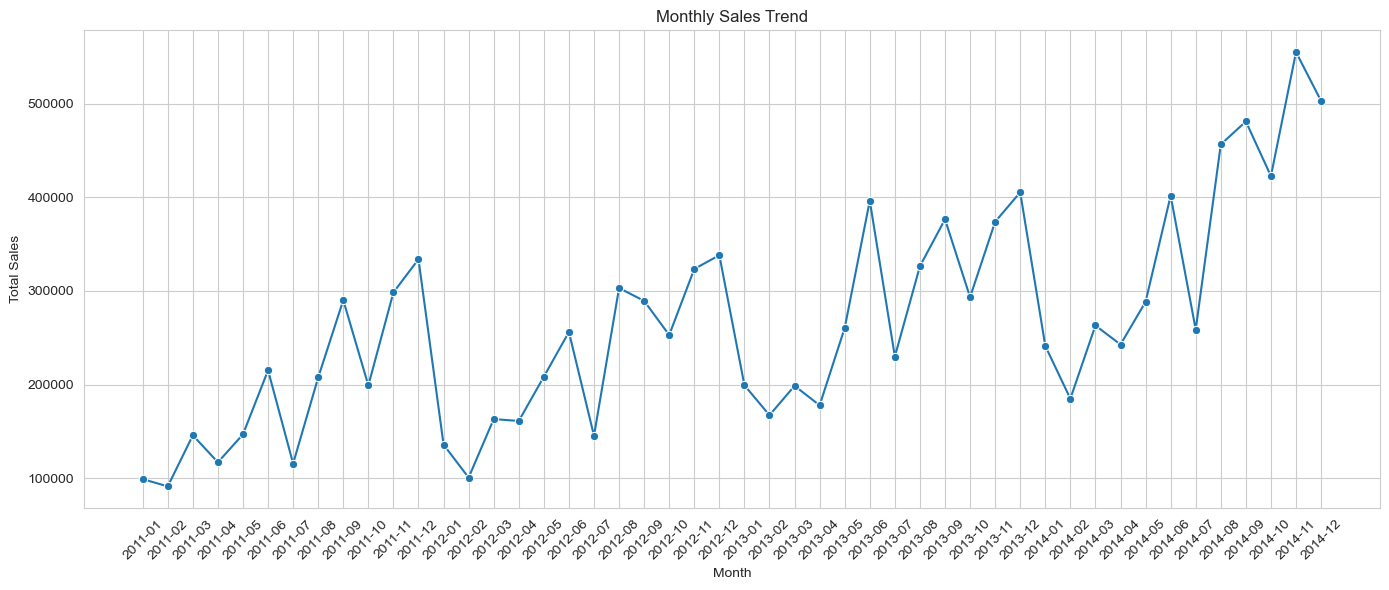

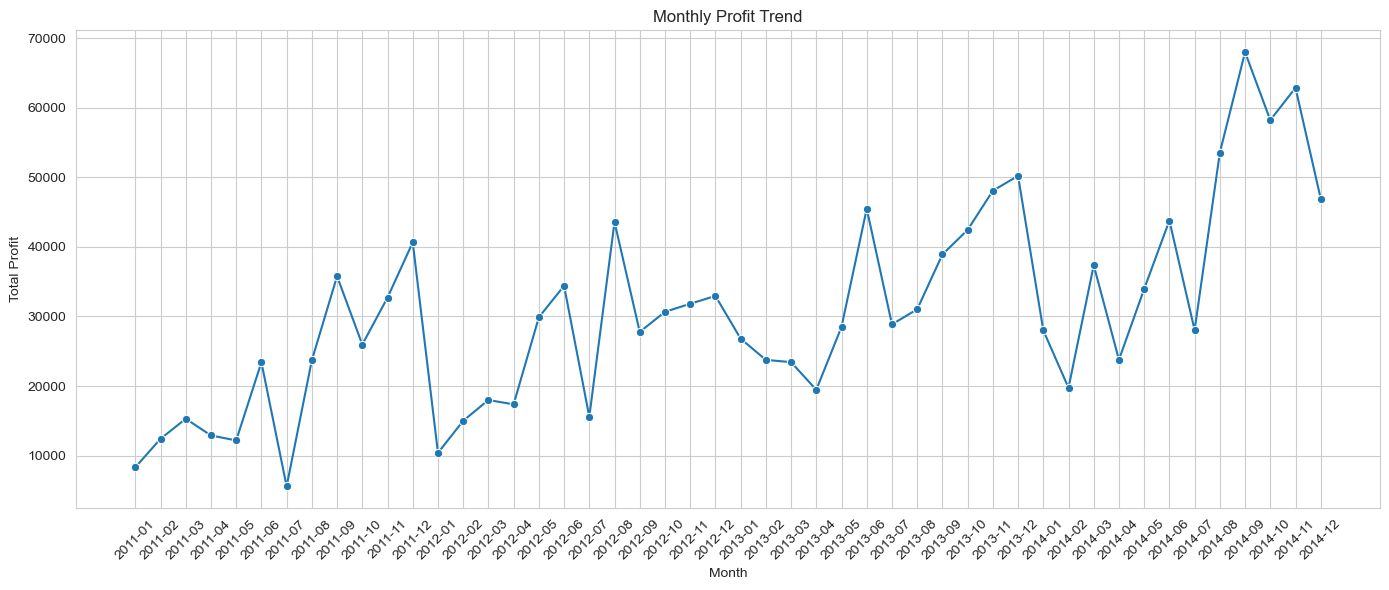

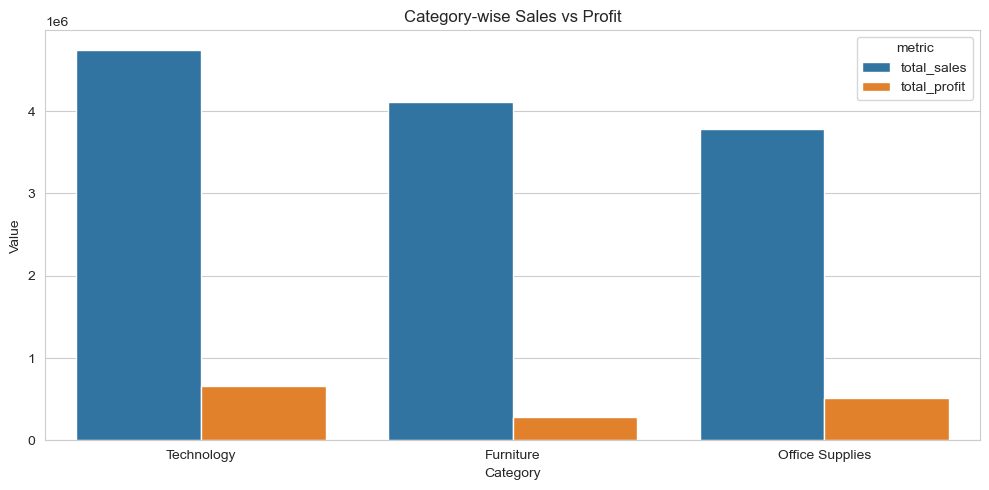

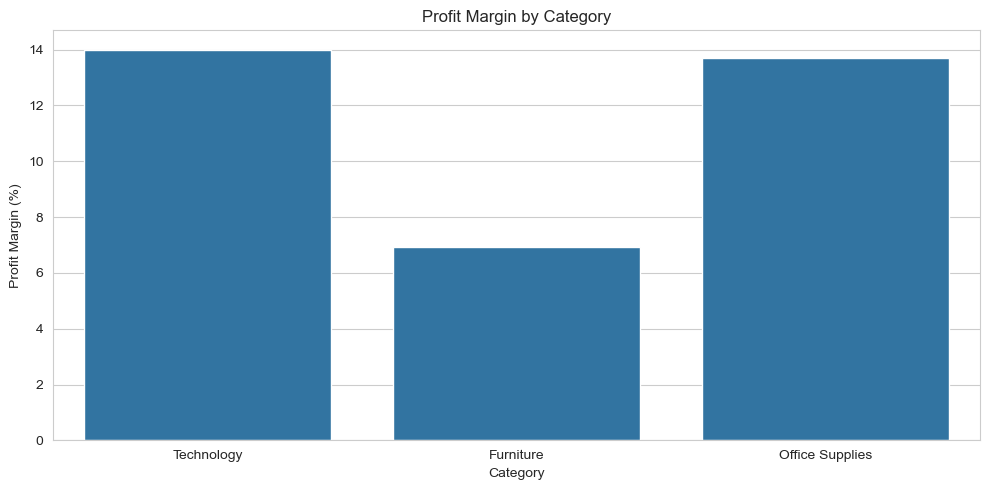

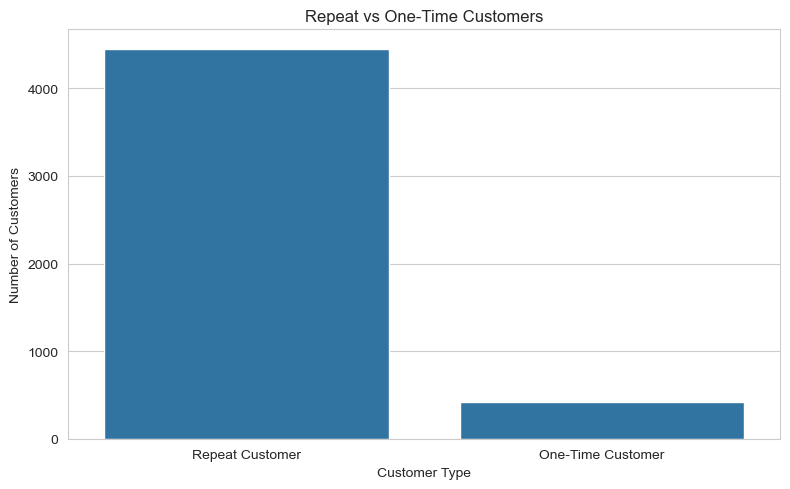

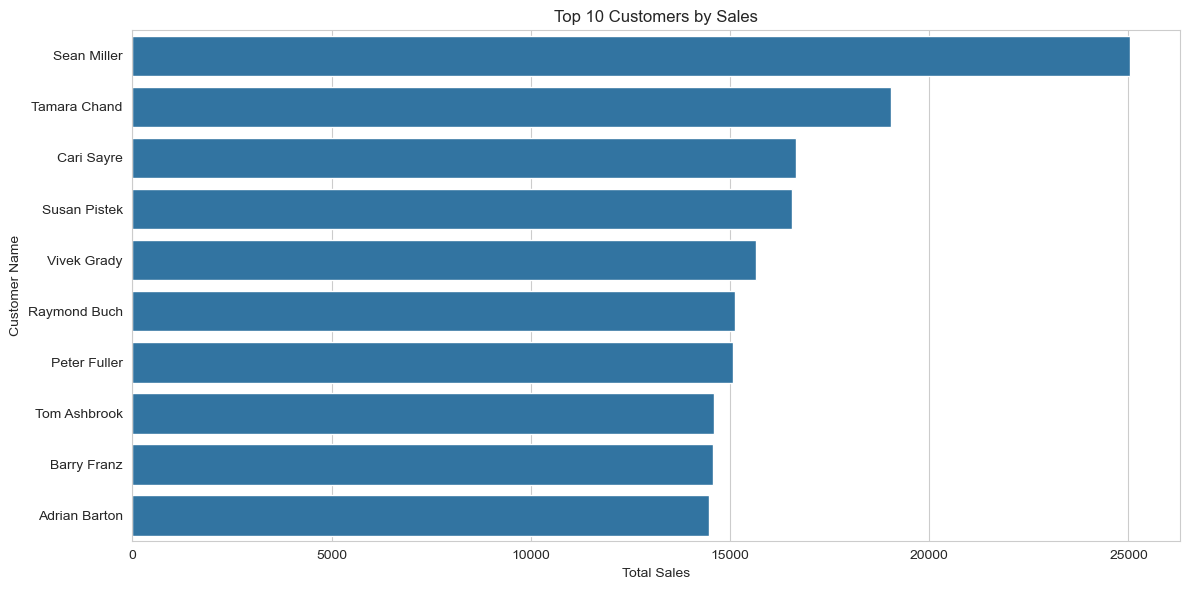

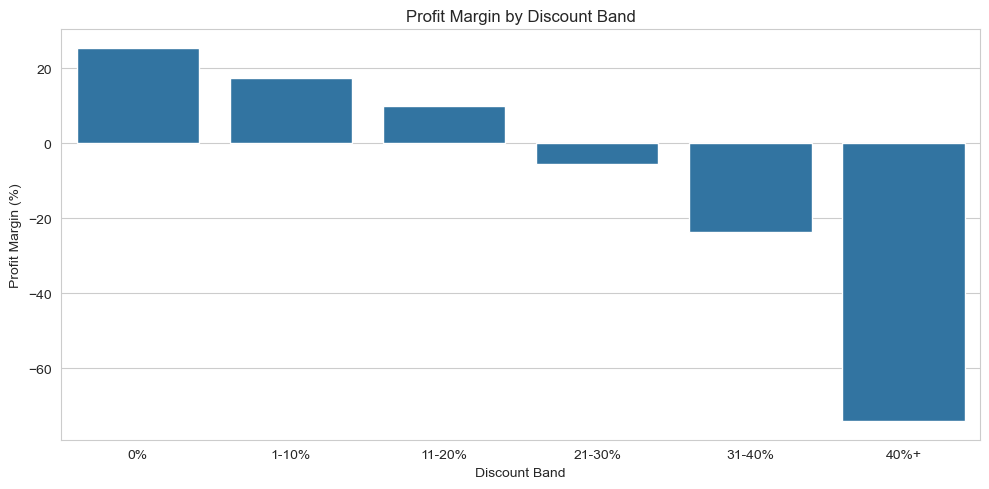

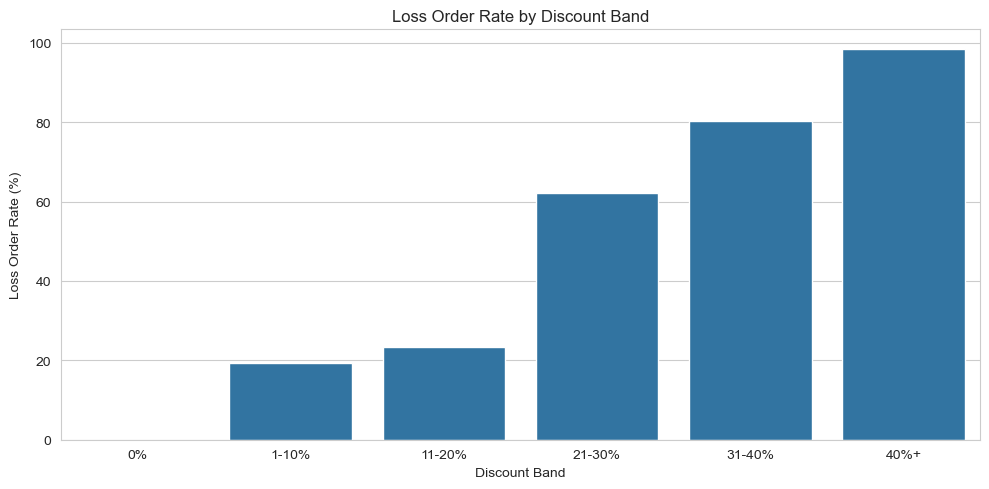

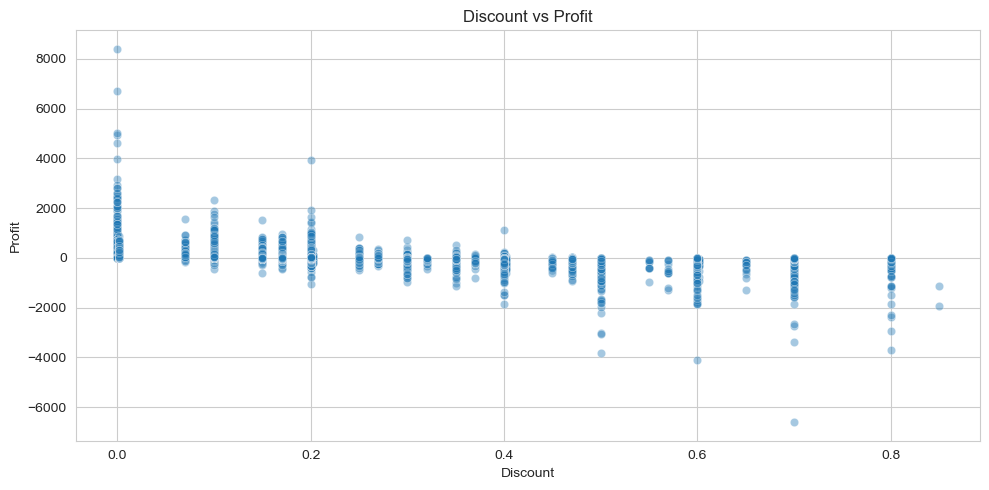

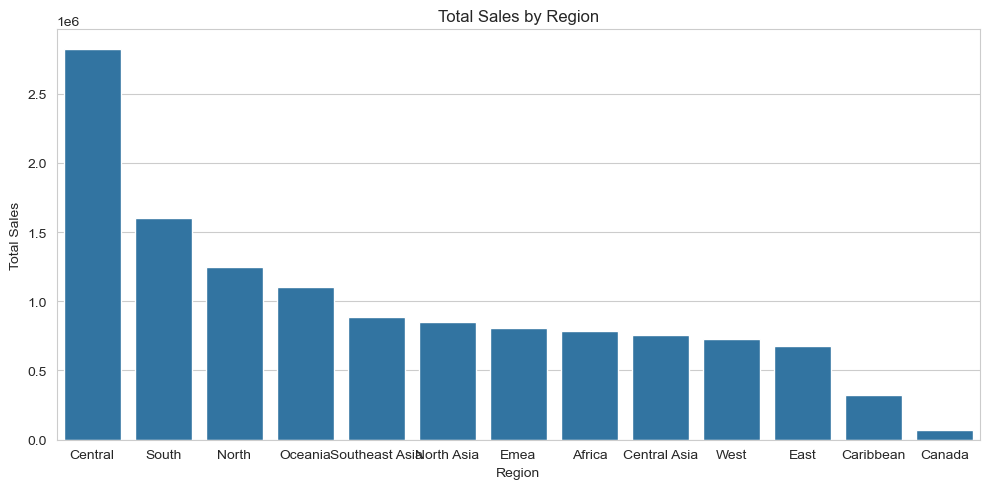

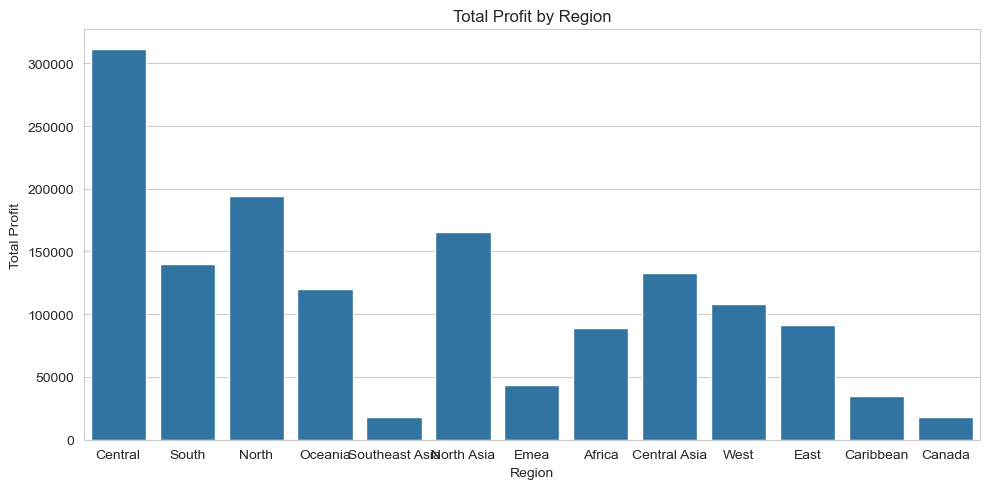

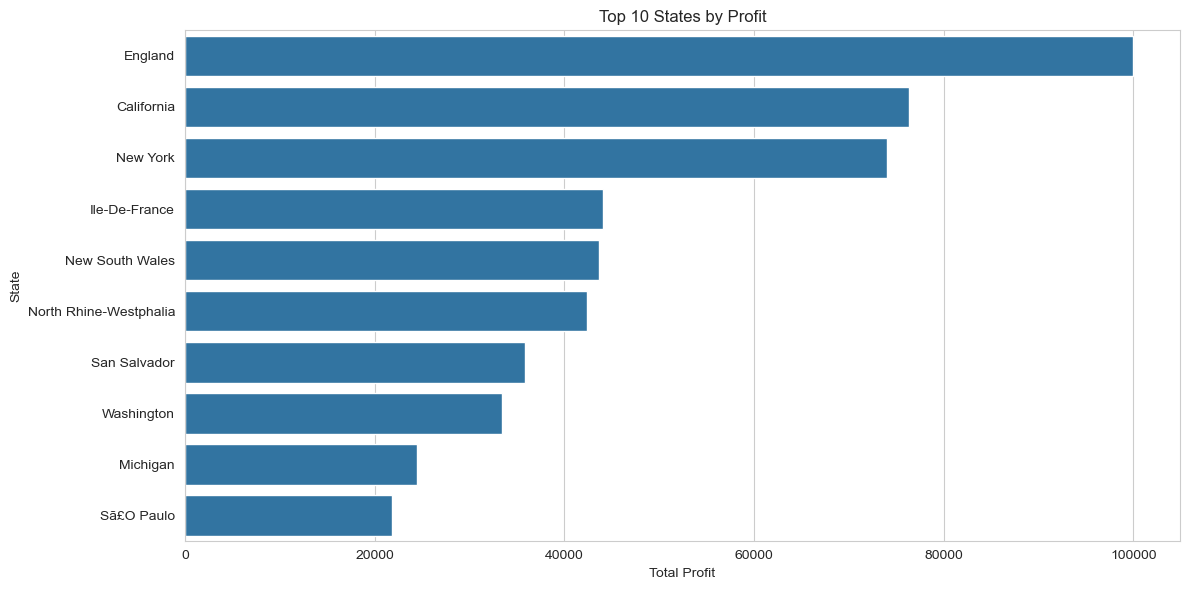

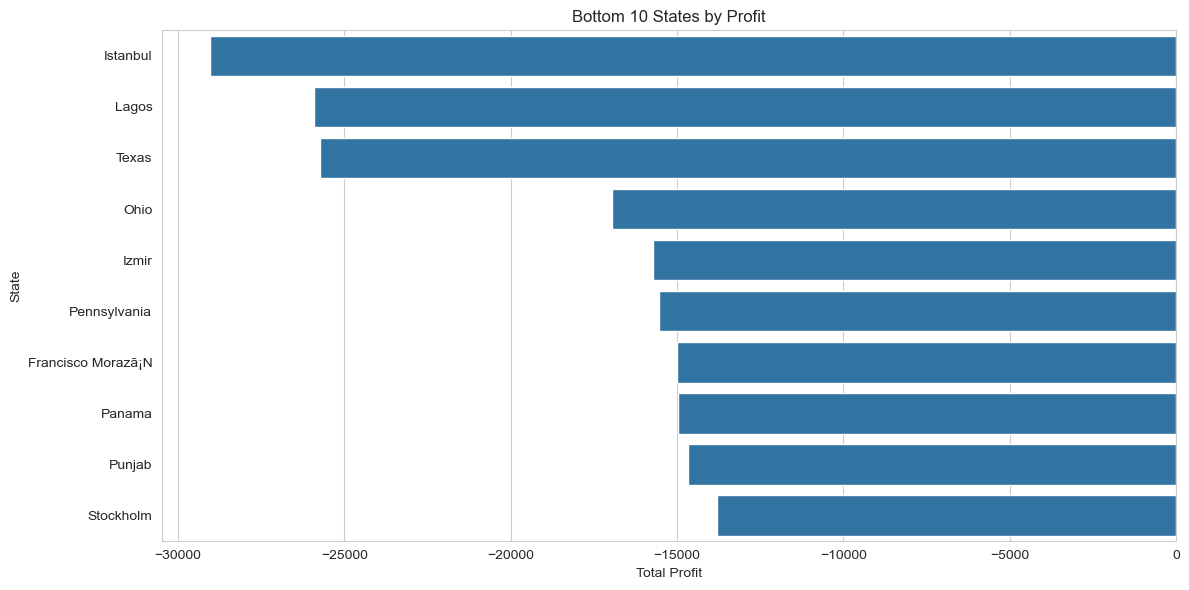

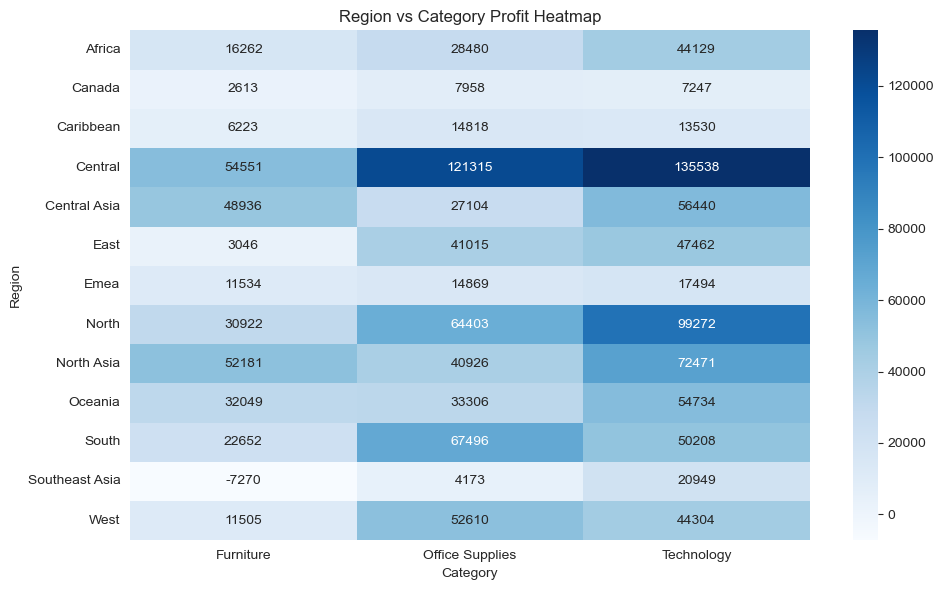


Visualization Insights:
1. Monthly charts show sales and profit trends over time.
2. Customer chart shows retention strength.
3. Discount charts show profit leakage points.
4. Regional charts show strong and weak markets.
5. Heatmap shows which categories work best by region.



In [ ]:
# ============================================================
# VISUALIZATION SECTION
# Purpose:
# Convert analysis tables into clear business charts.
# ============================================================


# ============================================================
# # 1. SETUP FOR CHARTS
# Purpose:
# Set chart size and style.
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)


# ============================================================
# # 2. MONTHLY SALES TREND
# Purpose:
# Shows revenue movement over time.
# ============================================================

plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_summary, x="year_month", y="total_sales", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================================
# # 3. MONTHLY PROFIT TREND
# Purpose:
# Shows profit movement over time.
# ============================================================

plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_summary, x="year_month", y="total_profit", marker="o")

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================================
# # 4. CATEGORY SALES VS PROFIT
# Purpose:
# Compare revenue and profitability by category.
# ============================================================

category_melted = category_summary.melt(
    id_vars="category",
    value_vars=["total_sales", "total_profit"],
    var_name="metric",
    value_name="value"
)

plt.figure(figsize=(10, 5))
sns.barplot(data=category_melted, x="category", y="value", hue="metric")

plt.title("Category-wise Sales vs Profit")
plt.xlabel("Category")
plt.ylabel("Value")
plt.tight_layout()
plt.show()


# ============================================================
# # 5. PROFIT MARGIN BY CATEGORY
# Purpose:
# Shows which categories are most efficient.
# ============================================================

plt.figure(figsize=(10, 5))
sns.barplot(data=category_summary, x="category", y="profit_margin")

plt.title("Profit Margin by Category")
plt.xlabel("Category")
plt.ylabel("Profit Margin (%)")
plt.tight_layout()
plt.show()


# ============================================================
# # 6. REPEAT VS ONE-TIME CUSTOMERS
# Purpose:
# Shows customer retention split.
# ============================================================

plt.figure(figsize=(8, 5))
sns.barplot(
    data=customer_type_distribution,
    x="customer_type",
    y="customer_count"
)

plt.title("Repeat vs One-Time Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


# ============================================================
# # 7. TOP 10 CUSTOMERS BY SALES
# Purpose:
# Identify highest-value customers.
# ============================================================

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_customers_by_sales,
    x="total_sales",
    y="customer_name"
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")
plt.tight_layout()
plt.show()


# ============================================================
# # 8. DISCOUNT BAND VS PROFIT MARGIN
# Purpose:
# Shows how discounts affect profitability.
# ============================================================

plt.figure(figsize=(10, 5))
sns.barplot(
    data=discount_summary,
    x="discount_band",
    y="profit_margin"
)

plt.title("Profit Margin by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Profit Margin (%)")
plt.tight_layout()
plt.show()


# ============================================================
# # 9. DISCOUNT BAND VS LOSS ORDER RATE
# Purpose:
# Shows where losses become frequent.
# ============================================================

plt.figure(figsize=(10, 5))
sns.barplot(
    data=discount_summary,
    x="discount_band",
    y="loss_order_rate"
)

plt.title("Loss Order Rate by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Loss Order Rate (%)")
plt.tight_layout()
plt.show()


# ============================================================
# # 10. DISCOUNT VS PROFIT SCATTER PLOT
# Purpose:
# Shows relationship between discount and profit.
# ============================================================

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="discount",
    y="profit",
    alpha=0.4
)

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()


# ============================================================
# # 11. REGION-WISE SALES
# Purpose:
# Compare revenue by region.
# ============================================================

plt.figure(figsize=(10, 5))
sns.barplot(
    data=regional_summary,
    x="region",
    y="total_sales"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


# ============================================================
# # 12. REGION-WISE PROFIT
# Purpose:
# Compare profitability by region.
# ============================================================

plt.figure(figsize=(10, 5))
sns.barplot(
    data=regional_summary,
    x="region",
    y="total_profit"
)

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.show()


# ============================================================
# # 13. TOP 10 STATES BY PROFIT
# Purpose:
# Find best geographic markets.
# ============================================================

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_states_by_profit,
    x="total_profit",
    y="state"
)

plt.title("Top 10 States by Profit")
plt.xlabel("Total Profit")
plt.ylabel("State")
plt.tight_layout()
plt.show()


# ============================================================
# # 14. BOTTOM 10 STATES BY PROFIT
# Purpose:
# Find weakest geographic markets.
# ============================================================

plt.figure(figsize=(12, 6))
sns.barplot(
    data=bottom_states_by_profit,
    x="total_profit",
    y="state"
)

plt.title("Bottom 10 States by Profit")
plt.xlabel("Total Profit")
plt.ylabel("State")
plt.tight_layout()
plt.show()


# ============================================================
# # 15. REGION + CATEGORY HEATMAP
# Purpose:
# Shows product performance across regions.
# ============================================================

region_category_pivot = region_category_summary.pivot_table(
    index="region",
    columns="category",
    values="total_profit",
    aggfunc="sum"
)

plt.figure(figsize=(10, 6))
sns.heatmap(region_category_pivot, annot=True, fmt=".0f", cmap="Blues")

plt.title("Region vs Category Profit Heatmap")
plt.xlabel("Category")
plt.ylabel("Region")
plt.tight_layout()
plt.show()


# ============================================================
# # 16. QUICK VISUALIZATION INSIGHTS
# ============================================================

print("""
Visualization Insights:
1. Monthly charts show sales and profit trends over time.
2. Customer chart shows retention strength.
3. Discount charts show profit leakage points.
4. Regional charts show strong and weak markets.
5. Heatmap shows which categories work best by region.
""")

In [ ]:
# Business Recommendations

## 1. Improve Customer Retention
A significant share of customers are one-time buyers. The company should focus on loyalty programs, personalized email campaigns, and targeted offers to increase repeat purchases.

## 2. Reduce Unprofitable Discounts
Higher discount bands show lower profit margins and more loss-making orders. Discounts above the identified threshold should be reviewed and used selectively.

## 3. Optimize Regional Strategy
Some regions generate strong sales but weaker profit margins. Region-specific pricing and product strategies can improve profitability.

## 4. Focus on High-Value Customers
Customers with the highest lifetime value should receive retention incentives and premium service to maximize long-term revenue.

## 5. Promote High-Margin Categories
Categories and sub-categories with consistently strong profit margins should be prioritized in marketing and sales efforts.